In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

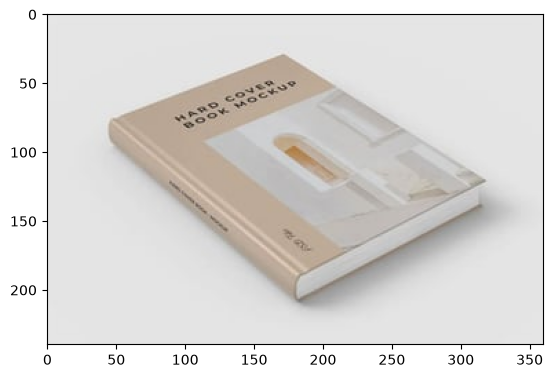

In [2]:
img = cv2.imread("book.jpg", cv2.IMREAD_COLOR_RGB)
h, w = img.shape[:2]

plt.imshow(img)
plt.show()

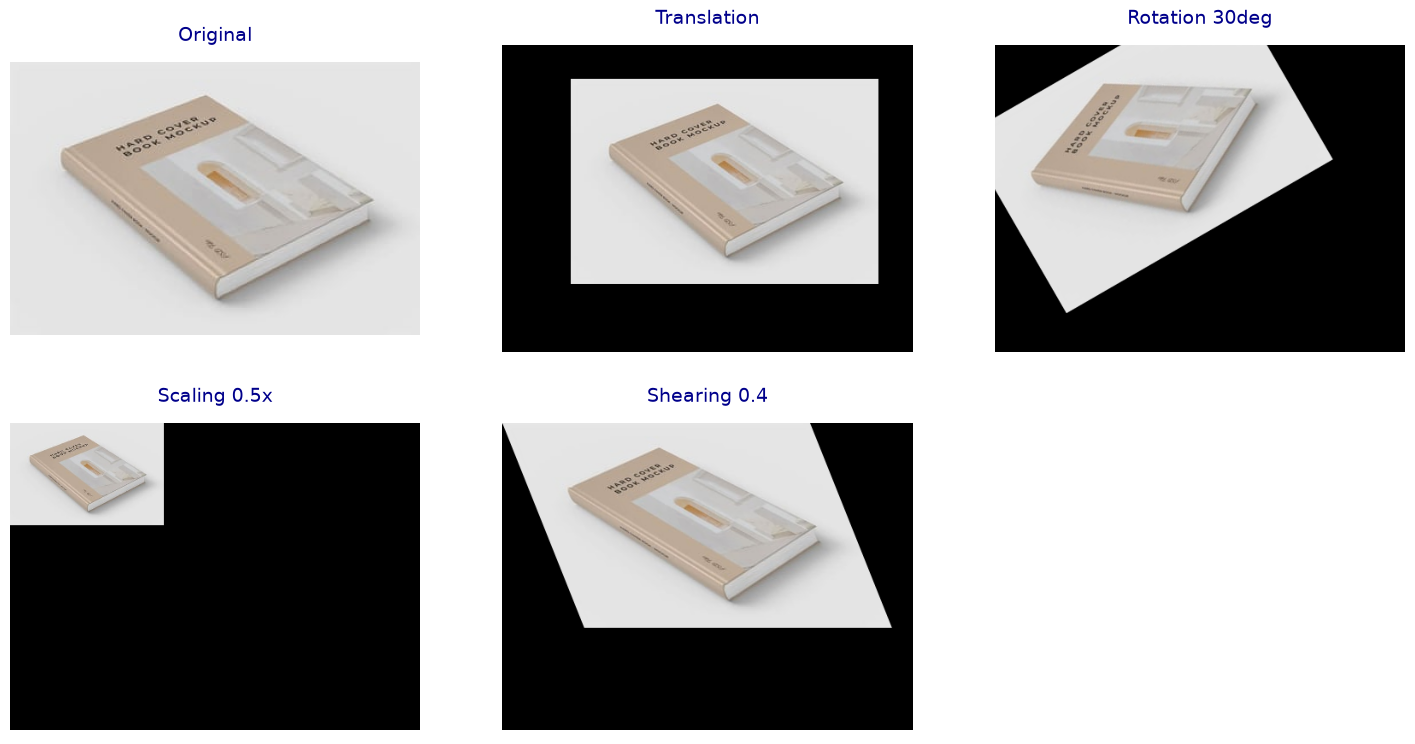

In [ ]:
# (a)
T = np.float32([[1, 0, 80], [0, 1, 40]])
R = cv2.getRotationMatrix2D((w / 2, h / 2), 30, 1)
S = np.float32([[0.5, 0, 0], [0, 0.5, 0]])
Sh = np.float32([[1, 0.4, 0], [0, 1, 0]])

panels = [('Original', img)]
for name, A in [('Translation', T), ('Rotation 30deg', R), ('Scaling 0.5x', S), ('Shearing 0.4', Sh)]:
    panels.append((name, cv2.warpAffine(img, A, (w + 120, h + 120))))

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()

for ax, (title, im) in zip(axes, panels):
    ax.imshow(im)
    ax.axis('off')
    ax.set_title(title, fontsize=14, color='darkblue', pad=15)

for ax in axes[len(panels):]:
    ax.axis('off')

plt.show()

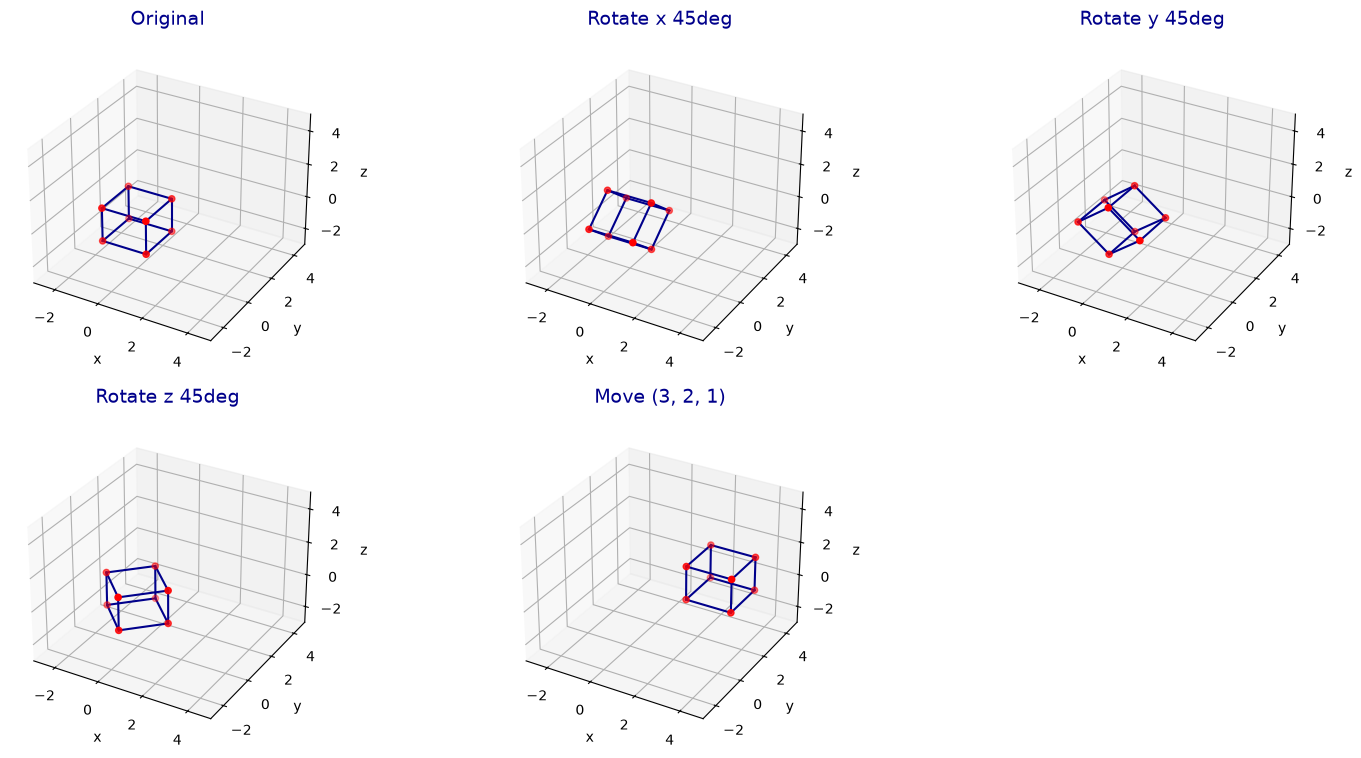

In [ ]:
# (b)
cube = np.float32([[x, y, z] for x in (-1, 1) for y in (-1, 1) for z in (-1, 1)])
edges = [(i, j) for i in range(8) for j in range(i + 1, 8) if np.sum(cube[i] != cube[j]) == 1]


def rot(axis, deg):
    t = np.deg2rad(deg)
    c, s = np.cos(t), np.sin(t)
    return {
        'x': np.float32([[1, 0, 0], [0, c, -s], [0, s, c]]),
        'y': np.float32([[c, 0, s], [0, 1, 0], [-s, 0, c]]),
        'z': np.float32([[c, -s, 0], [s, c, 0], [0, 0, 1]]),
    }[axis]


shapes = {
    'Original': cube,
    'Rotate x 45deg': cube @ rot('x', 45).T,
    'Rotate y 45deg': cube @ rot('y', 45).T,
    'Rotate z 45deg': cube @ rot('z', 45).T,
    'Move (3, 2, 1)': cube + np.float32([3, 2, 1]),
}

fig = plt.figure(figsize=(18, 9))
for i, (title, pts) in enumerate(shapes.items(), 1):
    ax = fig.add_subplot(2, 3, i, projection='3d')
    for a, b in edges:
        ax.plot(*zip(pts[a], pts[b]), color='darkblue')
    ax.scatter(*pts.T, color='red')
    ax.set_xlim(-3, 5)
    ax.set_ylim(-3, 5)
    ax.set_zlim(-3, 5)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    ax.set_title(title, fontsize=14, color='darkblue', pad=15)

plt.show()

In [ ]:
# (c)
p = np.float32([4, 3])
ph = np.append(p, 1)
print('homogeneous:', ph)

Th = np.float32([[1, 0, 5], [0, 1, 2], [0, 0, 1]])
print('translated:', Th @ ph)

print('(8, 6, 2):', (np.float32([8, 6, 2]) / 2)[:2])
print('direction after translation:', Th @ np.float32([1, 0, 0]))

homogeneous: [4. 3. 1.]
translated: [9. 5. 1.]
(8, 6, 2) ->  [4. 3.]
direction after translation: [1. 0. 0.]


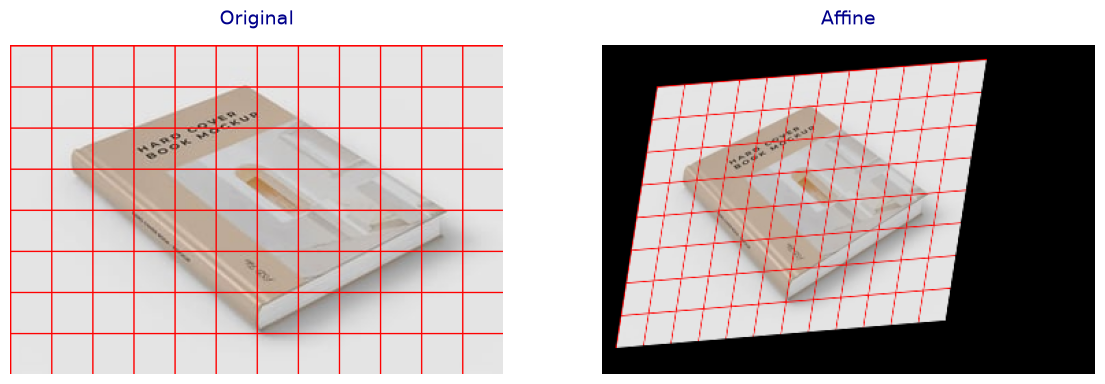

collinear before: 0.0
collinear after: 0.00024414062
parallel after: 6.1035156e-05


In [ ]:
# (d)
src = np.float32([[0, 0], [w - 1, 0], [0, h - 1]])
dst = np.float32([[40, 30], [w - 80, 10], [10, h - 20]])
A = cv2.getAffineTransform(src, dst)

grid = img.copy()
for x in range(0, w, 30):
    cv2.line(grid, (x, 0), (x, h), (255, 0, 0), 1)
for y in range(0, h, 30):
    cv2.line(grid, (0, y), (w, y), (255, 0, 0), 1)

panels = [('Original', grid), ('Affine', cv2.warpAffine(grid, A, (w, h)))]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes = axes.flatten()

for ax, (title, im) in zip(axes, panels):
    ax.imshow(im)
    ax.axis('off')
    ax.set_title(title, fontsize=14, color='darkblue', pad=15)

for ax in axes[len(panels):]:
    ax.axis('off')

plt.show()

cross = lambda a, b: a[0] * b[1] - a[1] * b[0]
line = np.float32([[[10, 10]], [[100, 55]], [[190, 100]]])
moved = cv2.transform(line, A).reshape(-1, 2)
print('collinear before:', cross(line[1, 0] - line[0, 0], line[2, 0] - line[0, 0]))
print('collinear after:', cross(moved[1] - moved[0], moved[2] - moved[0]))

d1 = cv2.transform(np.float32([[[0, 0]], [[100, 0]]]), A).reshape(-1, 2)
d2 = cv2.transform(np.float32([[[0, 50]], [[100, 50]]]), A).reshape(-1, 2)
print('parallel after:', cross(d1[1] - d1[0], d2[1] - d2[0]))

In [7]:
# (e) projective transformation (homography)
width, height = 200, 200
M = cv2.getPerspectiveTransform(
    np.float32([[50, 75], [170, 30], [315, 115], [195, 185]]),
    np.float32([[0, 0], [width, 0], [width, height], [0, height]])
)

M

array([[ 1.15529971e+00, -1.52289507e+00,  5.64521447e+01],
       [ 6.59834850e-01,  1.75955960e+00, -1.64958713e+02],
       [-2.63881520e-04,  2.68970240e-03,  1.00000000e+00]])

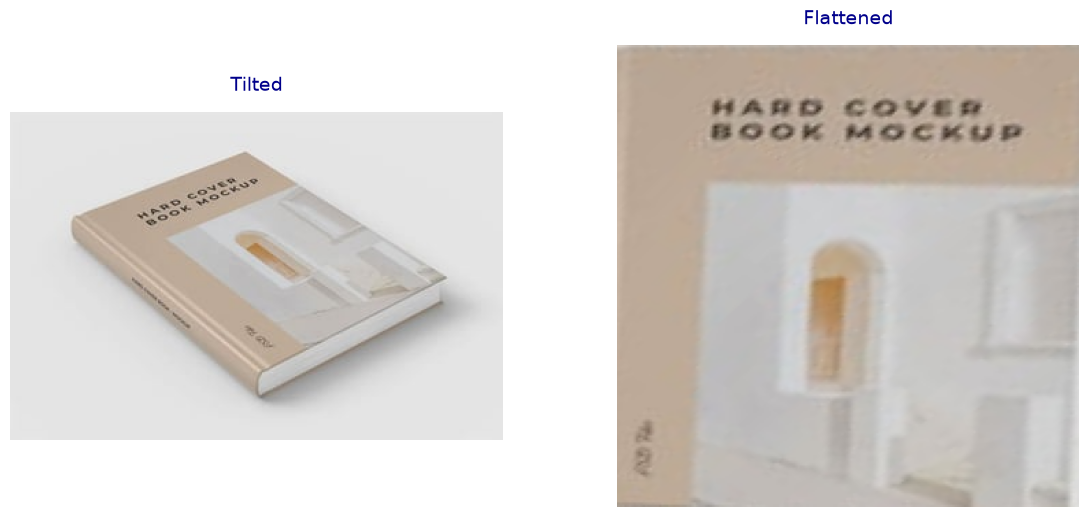

In [8]:
img_t = cv2.warpPerspective(img, M, (width, height))

panels = [('Tilted', img), ('Flattened', img_t)]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes = axes.flatten()

for ax, (title, im) in zip(axes, panels):
    ax.imshow(im)
    ax.axis('off')
    ax.set_title(title, fontsize=14, color='darkblue', pad=15)

for ax in axes[len(panels):]:
    ax.axis('off')

plt.show()